# 1. Data Load

Load the Bike Sharing Dataset, which contains daily records of bike rentals in a specific city. Use Python libraries to download, unzip, and load the dataset into a pandas DataFrame for further analysis.

- Import the necessary Python libraries: pandas, zipfile, io, and requests.
- Download the dataset using the provided URL and unzip it.
- Load the day.csv file, which contains the daily records, into a pandas DataFrame.
- Display the first few rows of the dataset to understand its structure and the type of data it contains.

In [18]:
import pandas as pd
import zipfile
import io
import requests

# Download and unzip the dataset
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00275/Bike-Sharing-Dataset.zip'
r = requests.get(url)
z = zipfile.ZipFile(io.BytesIO(r.content))
z.extractall()

# Load the day.csv file
bike_data = pd.read_csv('day.csv')

# Display the first few rows of the dataset
bike_data.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


# 2. Explore Data

In this section, we will explore the dataset visually to understand the distribution of the target variable (`cnt`) and its relationship with other features. Visualization helps in identifying patterns, trends, and potential correlations between variables.

- Import the necessary visualization libraries: `seaborn` and `matplotlib.pyplot`.
- Visualize the distribution of the target variable (`cnt`), which represents the total number of bike rentals, using a histogram.
- Use a pairplot to generate scatter plots for some features (e.g. `temp`, `atemp`, `hum`, `windspeed`) against the target variable (`cnt`). This helps in visualizing the relationships and identifying any potential linear or non-linear trends.

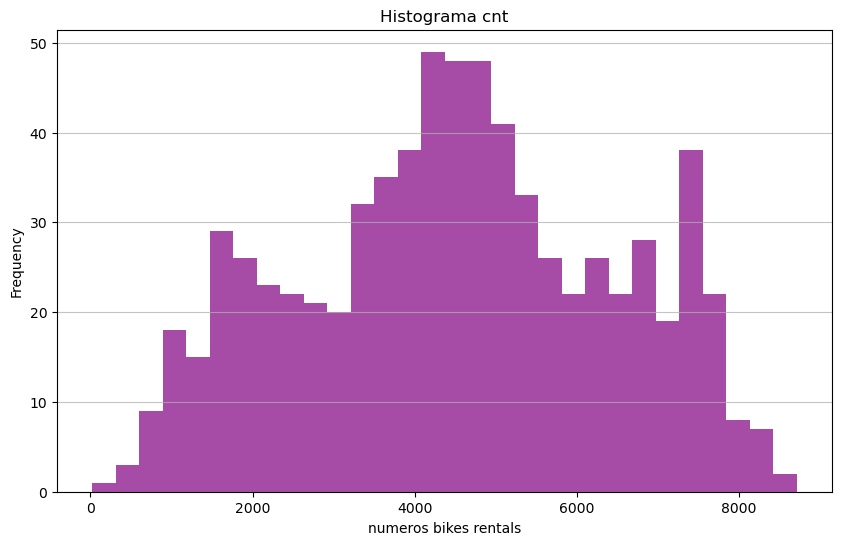

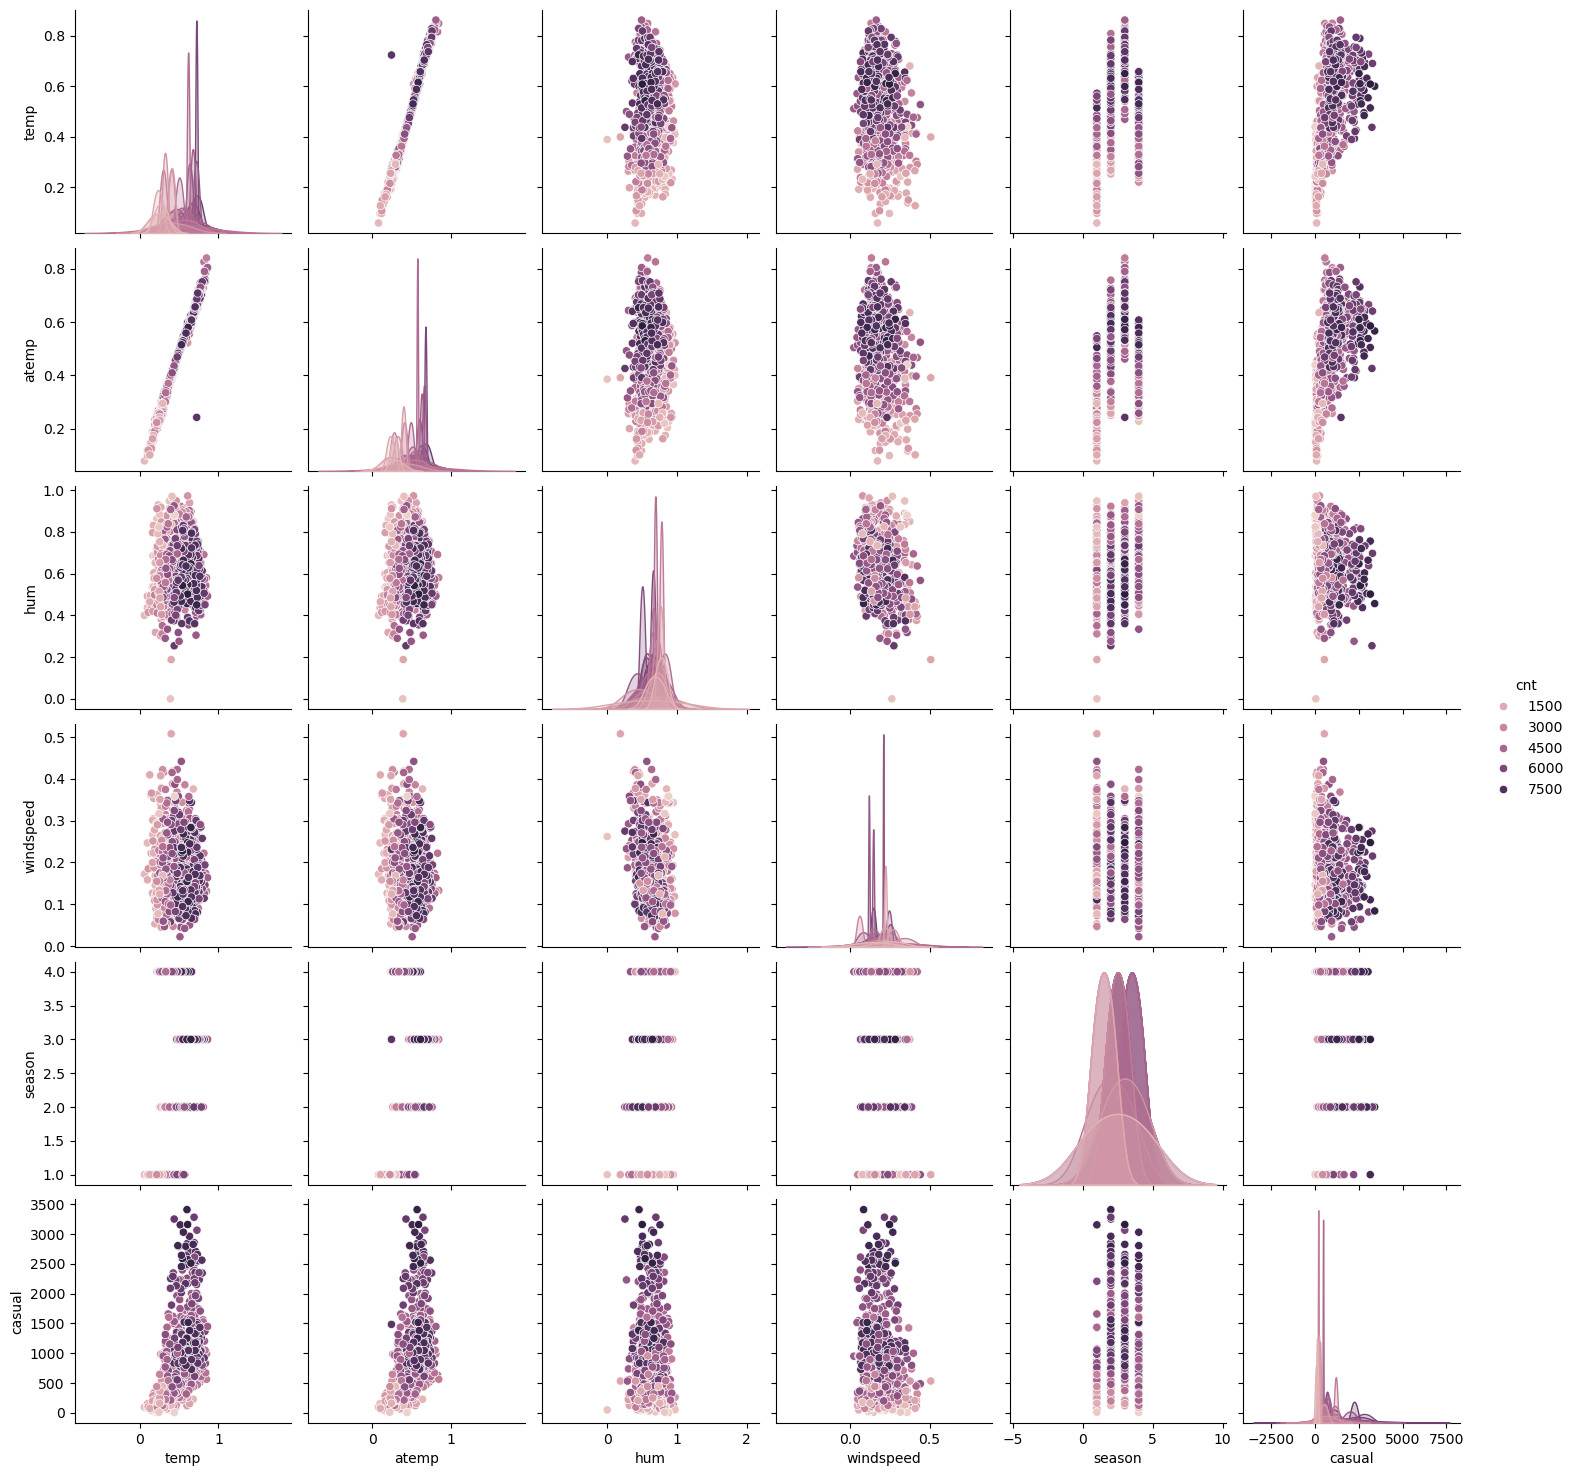

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualize the distribution of the target variable 'cnt' and some features
plt.figure(figsize=(10, 6))
plt.hist(bike_data['cnt'], bins=30, color='purple', alpha=0.7)
plt.title('Histograma cnt')
plt.xlabel('numeros bikes rentals')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()
# Scatter plot of some features against the target variable 'cnt'
selected_cols = ['temp', 'atemp','hum','windspeed','season','casual','cnt']

sns.pairplot(bike_data[selected_cols], hue = 'cnt')
plt.show()

# 3. Feature Selection

## 3.0 Remove the 'dteday' column as it is not needed for the analysis

Before proceeding with feature selection, we will remove the `dteday` column from the dataset since it represents the date and is not needed for our analysis. Keep in mind that our dataset already contains features that could be important, extracted from the date, such as `season`, `yr`, `mnth`, `holiday`, `weekday`, or `workingday`. These features are numerical, thus making them appropriate as features.


In [20]:
# borro 'dteday'
bike_data.drop('dteday', axis = 1, inplace = True)
bike_data.columns

Index(['instant', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered', 'cnt'],
      dtype='object')

## 3.1 Explore the correlation with the target variable and select the best features

In this step, we will explore the correlation between the features and the target variable (`cnt`). This helps in identifying which features are most strongly associated with the number of bike rentals.

- Generate a correlation matrix to examine the relationships between all features and the target variable.
- Visualize the correlation matrix using a heatmap to easily identify the strength of the relationships.
- Select features that show a high correlation with the target variable (cnt) for further analysis. For this, we will manually select features with a correlation coefficient greater than 0.5. Later, we will use regularization techniques (like Lasso or Ridge) to refine the selection and further reduce multicollinearity.



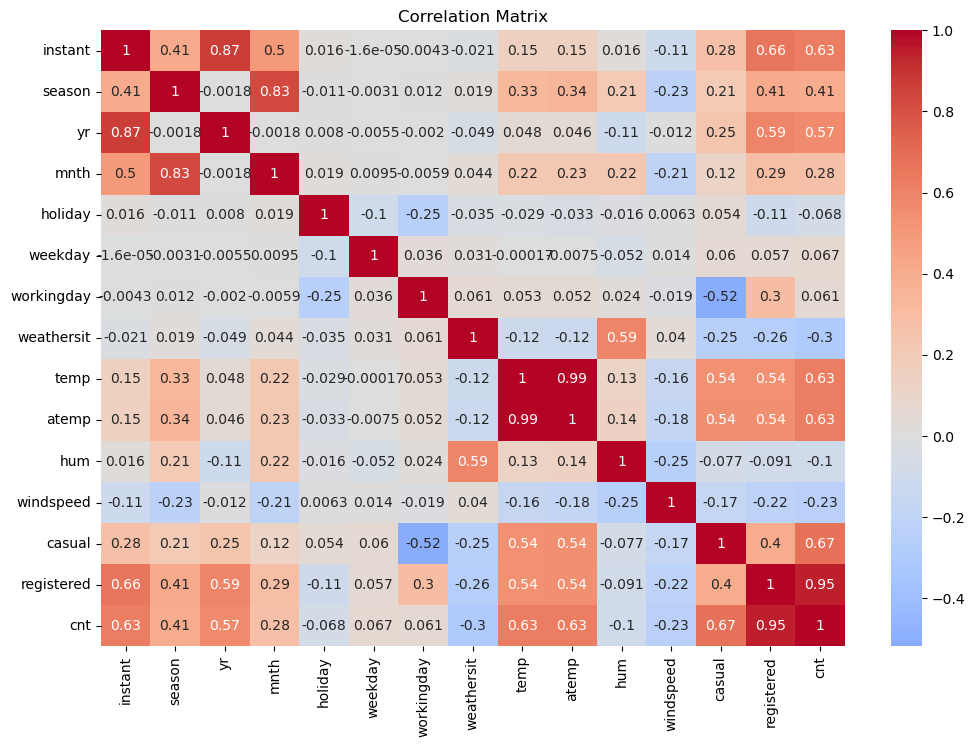

Features with correlation > 0.5 with cnt:
instant       0.628830
yr            0.566710
temp          0.627494
atemp         0.631066
casual        0.672804
registered    0.945517
Name: cnt, dtype: float64


In [67]:
# Correlation matrix
# Calcular la matriz de correlación
corr_matrix = bike_data.corr()

# Visualizar la matriz de correlación
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center = 0)
plt.title('Correlation Matrix')
plt.show()

# Seleccionar características con correlación > 0.5 con 'cnt'
high_corr_features = corr_matrix['cnt'][corr_matrix['cnt'].abs() > 0.5].drop('cnt')
print("Features with correlation > 0.5 with cnt:")
print(high_corr_features)


## 3.2 Explore multicollinearity among features

Multicollinearity occurs when features are highly correlated with each other, which can negatively affect the performance of regression models. When features are multicollinear, it becomes difficult for the model to determine the individual effect of each feature, as they are providing overlapping information. To handle this issue and improve the model's accuracy, we need to check for multicollinearity among the selected features.

### Steps to follow:

1. **Calculate the Variance Inflation Factor (VIF)** for each feature. The VIF measures how much the variance of the estimated regression coefficients increases when your predictors are correlated. A high VIF indicates that the feature is highly correlated with other features in the dataset. Generally, a VIF value above **5 or 10** suggests problematic multicollinearity.

2. **Interpret the VIF values**:
   - Features with a **low VIF** (close to 1) are **not highly correlated** with others and are safe to keep in the model.
   - Features with **high VIF** values are **highly correlated** with other features and should be considered for removal if they do not provide meaningful or unique information.

3. **Decision Making**:
   - **Remove features with excessively high VIF** (e.g., above 10), especially when they are highly correlated with other predictors and do not add unique interpretability to the model. For example, if `temp` and `atemp` are very similar, consider keeping only one (e.g., `temp`).
   - If features like `registered` are strongly related to other predictors (e.g., `casual`) or to the target variable (`cnt`), they should be excluded to prevent overfitting.
   - Retain variables that either provide relevant information or will be used to explore how different models handle multicollinearity, even if their VIF is higher than usual.

4. **Example Features to Keep**:
   Based on the VIF analysis, you may choose to keep features such as `yr`, `casual`, `temp`, and `instant`. While some of these may show moderate or high multicollinearity, they can still be useful for analyzing how linear and regularized regression models handle correlated features. In contrast, variables like `registered` or `atemp` may be removed due to redundancy or excessive VIF values.

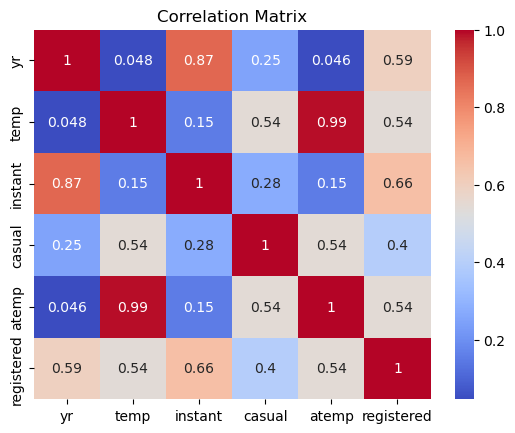

      Feature         VIF
3      casual    3.774705
0          yr    8.728598
2     instant   17.136429
5  registered   18.752383
1        temp  438.374729
4       atemp  460.234316


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
# nos quedamos con estas features por su correlacion > 0.5
features = bike_data[['yr','temp', 'instant','casual','atemp','registered']]

correlation_matrix = features.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Calculating VIF (Variance Inflation Factor) to check for multicollinearity
# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data['Feature'] = features.columns
vif_data['VIF'] = [variance_inflation_factor(features.values, i) for i in range(features.shape[1])]

print(vif_data.sort_values(by='VIF'))

# con estos resultados me quedo con 'casual','yr','registered','temp


# 4. Generate a Linear Regression Model

In this section, we will create a linear regression model to predict the total number of bike rentals (`cnt`) using the selected features. We will train the model, visualize its predictions, and evaluate its performance.

- Import the necessary libraries: `train_test_split`, `LinearRegression`, `mean_squared_error`, and `r2_score` from `sklearn`.
- Select the relevant features for the linear regression model based on correlation analysis.
- Split the data into training and testing sets to evaluate the model's performance on unseen data.
- Create and train the linear regression model using the training data.

In [74]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Selecting features for linear regression based on correlation analysis
select_feature = ['casual','yr','temp']
X = bike_data[select_feature]
y = bike_data['cnt']
# Splitting data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Creating and training the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

## 4.1 Plot the result with one feature and the target variable to check how it fits

After training the linear regression model, we will visualize its predictions against the actual values to understand how well the model fits the data.

- Use the trained model to make predictions on the test set.
- Plot the actual versus predicted values for one of the features (`temp`) to visually assess the model's performance.

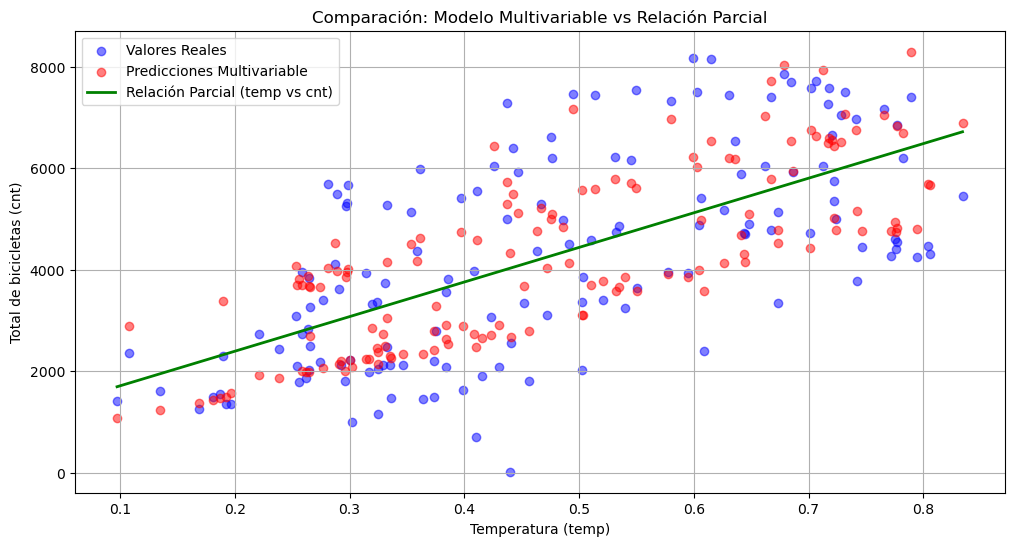

In [83]:

# 1. Datos de ejemplo (asumiendo que ya tienes X_train, X_test, y_train, y_test)
# Seleccionamos solo 'temp' para el plot (aunque el modelo usa múltiples features)
temp_test = X_test['temp'].values.reshape(-1, 1)

# 2. Crear un modelo auxiliar SOLO para visualización (regresión simple entre temp y cnt)
model_aux = LinearRegression()
model_aux.fit(temp_test, y_test)

# 3. Generar puntos para la línea de regresión
x_plot = np.linspace(temp_test.min(), temp_test.max(), 100).reshape(-1, 1)
y_plot = model_aux.predict(x_plot)

# 4. Plot completo
plt.figure(figsize=(12, 6))

# Valores reales
plt.scatter(temp_test, y_test, color='blue', alpha=0.5, label='Valores Reales')

# Predicciones del modelo multivariable (pero ploteando solo vs temp)
plt.scatter(temp_test, y_pred, color='red', alpha=0.5, label='Predicciones Multivariable')

# Línea de regresión simple (temp vs cnt)
plt.plot(x_plot, y_plot, 'g-', linewidth=2, label='Relación Parcial (temp vs cnt)')

plt.xlabel('Temperatura (temp)')
plt.ylabel('Total de bicicletas (cnt)')
plt.title('Comparación: Modelo Multivariable vs Relación Parcial')
plt.legend()
plt.grid(True)
plt.show()

## 4.2 Evaluate the model with MSE and R2

Finally, we will evaluate the linear regression model's performance using Mean Squared Error (MSE) and R-squared (R²) metrics. These metrics will help us understand the accuracy and explanatory power of the model.

- Predict the target variable (`cnt`) using the test data.
- Calculate the MSE to measure the average squared difference between the predicted and actual values.
- Calculate the R² score to determine the proportion of the variance in the target variable that is predictable from the features.

In [25]:
# Predicting on the test set


# Evaluating the model


# 5. Generate a Polynomial Regression Model (degree 2)

In this section, we will extend the linear regression model by generating a polynomial regression model of degree 2. Polynomial regression allows us to model non-linear relationships between the features and the target variable.

- Import the necessary libraries: `PolynomialFeatures` and `make_pipeline` from `sklearn.preprocessing`.
- Create polynomial features from the selected features (`temp`, `hum`) to capture the non-linear relationships.
- Train the polynomial regression model using these polynomial features.

In [26]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Creating and training the Polynomial Regression model (degree 2)


## 5.1 Plot the results to see how it fits

After training the polynomial regression model, we will visualize its predictions against the actual values to understand how well the model fits the data.

- Use the trained model to make predictions on the test set.
- Plot the actual versus predicted values for one of the features (`temp`) to visually assess the model's performance.

In [27]:
# Predicting and plotting results for the 'temp' feature


## 5.2 Evaluate the model with MSE and R2

Finally, we will evaluate the polynomial regression model's performance using Mean Squared Error (MSE) and R-squared (R²) metrics. These metrics will help us understand the accuracy and explanatory power of the model.

- Predict the target variable (`cnt`) using the test data.
- Calculate the MSE to measure the average squared difference between the predicted and actual values.
- Calculate the R² score to determine the proportion of the variance in the target variable that is predictable from the features.

In [28]:
# Evaluating the polynomial regression model



# 6. Compare the results between LR and PR

In this section, we will compare the performance of the Linear Regression (LR) and Polynomial Regression (PR) models to understand which model better fits the data.

- Use the Mean Squared Error (MSE) and R-squared (R²) metrics calculated in the previous sections to compare the two models.
- Print the MSE and R² scores for both the Linear Regression and Polynomial Regression models.
- Analyze the results: A lower MSE indicates a better fit, while a higher R² indicates a better explanation of the variance in the target variable. Compare these metrics to determine whether the Polynomial Regression model provides a significant improvement over the Linear Regression model.

In [29]:
# print and compare the results of the linear and polynomial regression models


# 7. Use Lasso and Ridge to Test the Features

In this section, we will apply two regularization techniques—Lasso and Ridge regression—to both linear and polynomial regression models. Both methods add a penalty to the regression model to reduce overfitting and improve generalization, but they do so in different ways.

## 7.1 Lasso Regression

Lasso regression adds a penalty equal to the absolute value of the magnitude of coefficients. This technique is particularly useful for feature selection as it can shrink some coefficients to zero, effectively removing those features from the model.

### 7.1.1 Lasso Regression on Linear Features

- Import the `Lasso` class from `sklearn.linear_model`.
- Create and train the Lasso regression model using the linear features from the training data.
- Use the trained model to make predictions on the test set.
- Calculate the Mean Squared Error (MSE) and R-squared (R²) scores to evaluate the performance of the Lasso model.

In [30]:
from sklearn.linear_model import Lasso

# Lasso Regression on Linear Features


### 7.1.2 Lasso Regression on Polynomial Features

- Apply `PolynomialFeatures` to the training and test data to create polynomial features.
- Create and train the Lasso regression model using the polynomial features.
- Use the trained model to make predictions on the test set.
- Calculate the MSE and R² scores to evaluate the performance of the Lasso model with polynomial features.

In [31]:
# Lasso Regression on Polynomial Features



## 7.2 Ridge Regression

Ridge regression adds a penalty equal to the square of the magnitude of coefficients. This technique is effective for handling multicollinearity in the dataset and preventing overfitting by shrinking the coefficients.

### 7.2.1 Ridge Regression on Linear Features

- Import the `Ridge` class from `sklearn.linear_model`.
- Create and train the Ridge regression model using the linear features from the training data.
- Use the trained model to make predictions on the test set.
- Calculate the MSE and R² scores to evaluate the performance of the Ridge model.

In [32]:
from sklearn.linear_model import Ridge

# Ridge Regression on Linear Features



### 7.2.2 Ridge Regression on Polynomial Features

- Apply `PolynomialFeatures` to the training and test data to create polynomial features.
- Create and train the Ridge regression model using the polynomial features.
- Use the trained model to make predictions on the test set.
- Calculate the MSE and R² scores to evaluate the performance of the Ridge model with polynomial features.

In [33]:
# Ridge Regression on Polynomial Features



# 8. Compare the Results of Linear, Polynomial, Ridge, and Lasso Regression Models

In this section, we will compare the performance of various regression models—Linear, Polynomial, Ridge, and Lasso—using the evaluation metrics we calculated: Mean Squared Error (MSE) and R-squared (R²). This comparison will help us understand which model best fits the data and offers the most accurate predictions.

- **Review the MSE and R² scores** for each model: Linear Regression, Polynomial Regression, Ridge Regression (both linear and polynomial), and Lasso Regression (both linear and polynomial).
- **Compare the MSE values**: A lower MSE indicates a better fit to the data. Compare the MSE values across all models to determine which one minimizes the error.
- **Compare the R² values**: A higher R² score indicates that the model explains a greater proportion of the variance in the target variable. Compare the R² scores to identify which model has the best explanatory power.

- Discuss your findings:
  - Which model has the lowest MSE?
  - Which model has the highest R²?
  - How do the regularization techniques (Ridge and Lasso) affect model performance compared to the standard Linear and Polynomial models?
  - Consider the trade-offs between model complexity (Polynomial Regression) and simplicity (Linear Regression) when choosing the best model for prediction.

In [34]:
# Print and compare all the models


# 9. Use GridSearchCV to Find the Best Model with Several Parameters

In this section, we will use `GridSearchCV` to optimize the Polynomial Ridge Regression model by searching for the best hyperparameters. `GridSearchCV` automates the process of tuning hyperparameters by testing a range of values and selecting the ones that result in the best model performance.

## 9.1 Perform Grid Search for Ridge Regression

In this step, we will perform a **Grid Search** to tune the **Ridge Regression model** with polynomial features. The goal is to find the best hyperparameter (`alpha`) for the model using cross-validation.

1. **Import the necessary libraries**:
   - Import `GridSearchCV` from `sklearn.model_selection` for performing the grid search.
   - Import `PolynomialFeatures` from `sklearn.preprocessing` to create polynomial features.
   - Import `Ridge` from `sklearn.linear_model` for the Ridge Regression model.
   - Use `Pipeline` from `sklearn.pipeline` to chain the polynomial transformation and Ridge regression together.

2. **Define the parameter grid** for Ridge Regression:
   - We will tune the `alpha` parameter, which controls the strength of the regularization. You can define a grid of possible `alpha` values to try, such as `[0.1, 1.0, 10.0, 100.0]`.

3. **Use `GridSearchCV`** to find the best `alpha` value:
   - `GridSearchCV` will perform cross-validation to search for the best `alpha` by training and evaluating the model on the training data.
   
4. **Train the Ridge Regression model**:
   - After performing the grid search, train the model using the best `alpha` parameter found by `GridSearchCV`.

5. **Evaluate the model**:
   - Use **Mean Squared Error (MSE)** and **R-squared (R²)** metrics to evaluate the performance of the model on the test data.

In [35]:
from sklearn.model_selection import GridSearchCV

# Parameter grid for Ridge regression
param_grid = {'alpha': [0.1, 1.0, 10.0, 100.0]}

# Grid search for Ridge regression




# 10. Compare the MSE and R² Results for All Models

- After obtaining the optimized Ridge Regression model, compare its performance with the Linear, Polynomial, Lasso, and initial Ridge Regression models.
- Print the MSE and R² scores for all models to determine which model provides the best balance of predictive accuracy and generalization.

In [36]:
# Print and compare all the models

